In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [42]:
NUM_WORDS = 10000
MAX_LENGTH = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=NUM_WORDS
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", np.unique(y_train))

Training samples: 25000
Testing samples: 25000
Classes: [0 1]


In [43]:
NUM_WORDS = 10000
MAX_LENGTH = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=NUM_WORDS
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", np.unique(y_train))

Training samples: 25000
Testing samples: 25000
Classes: [0 1]


In [44]:
X_train = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (25000, 200)
X_test shape: (25000, 200)


In [70]:
model = Sequential([
    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=NUM_WORDS,
        output_dim=64
    ),

    LSTM(32),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,449 (2.49 MB)

 Trainable params: 652,449 (2.49 MB)

 Non-trainable params: 0 (0.00 B)

In [72]:
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    min_lr=1e-6
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping,reduce_lr]
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.5225 - loss: 0.6912 - val_accuracy: 0.5394 - val_loss: 0.6848 - learning_rate: 0.0010
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.5361 - loss: 0.7014 - val_accuracy: 0.5412 - val_loss: 0.6832 - learning_rate: 0.0010
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5884 - loss: 0.6531 - val_accuracy: 0.6190 - val_loss: 0.6126 - learning_rate: 0.0010
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6975 - loss: 0.5916 - val_accuracy: 0.7444 - val_loss: 0.5455 - learning_rate: 0.0010
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7909 - loss: 0.5039 - val_accuracy: 0.7924 - val_loss: 0.4977 - learning_rate: 0.0010
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8316 - loss: 0.4369 - val_accuracy: 0.7932 - val_loss: 0.4964 - learning_rate: 0.0010
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8227 - loss: 0.

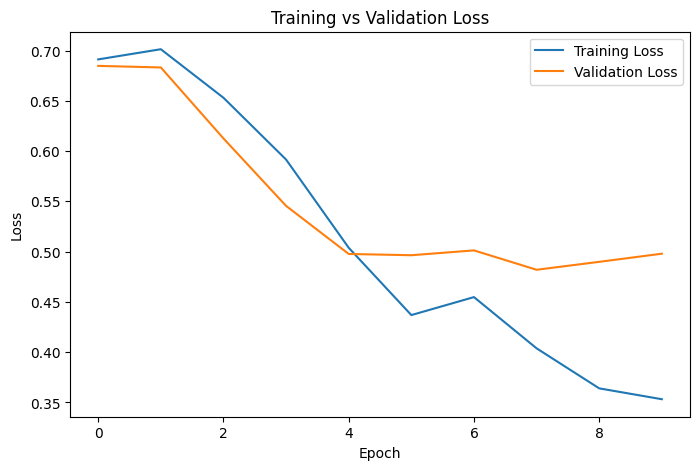

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

In [74]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.5074436664581299
Test Accuracy: 0.7917199730873108


In [75]:
y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("Actual shape   :", y_test.shape)
print("Prediction shape:", y_pred.shape)

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
Actual shape   : (25000,)
Prediction shape: (25000,)


In [76]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("========== CLASSIFICATION METRICS ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

========== CLASSIFICATION METRICS ==========
Accuracy  : 0.7917
Precision : 0.7751
Recall    : 0.8219
F1-Score  : 0.7978


In [77]:
class_names = [
    "Negative",
    "Positive"
]

print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    Negative       0.81      0.76      0.79     12500
    Positive       0.78      0.82      0.80     12500

    accuracy                           0.79     25000
   macro avg       0.79      0.79      0.79     25000
weighted avg       0.79      0.79      0.79     25000



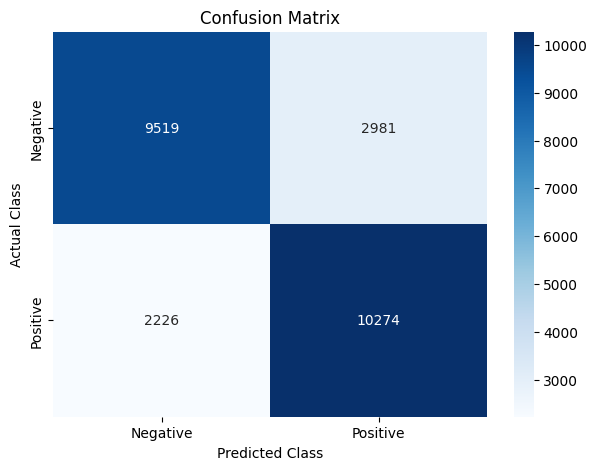

In [78]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")

plt.show()